# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

In [1]:
import sqlite3, numpy as np, pandas as pd, matplotlib.pyplot as plt

DB_PATH = 'inventory_and_sales.db'      # path in your repo or Colab
STORES_CSV = 'store_locations.csv'
LANDFALL = pd.Timestamp('2024-09-25')   # busiest day; confirm against your chart
BASELINE_START, BASELINE_END = pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')
PEAK_START, PEAK_END = pd.Timestamp('2024-09-24'), pd.Timestamp('2024-09-25')
TOP_N = 5

def tidy(ax):
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)

con = sqlite3.connect(DB_PATH)
d = pd.read_sql('select * from daily_sales_summary', con)
d['date'] = pd.to_datetime(d['date'], format='mixed')   # mixes 2024-09-01 and 20240912
d = d.drop_duplicates()
daily = d.groupby(['date', 'category'])['total_units'].sum().unstack()

### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

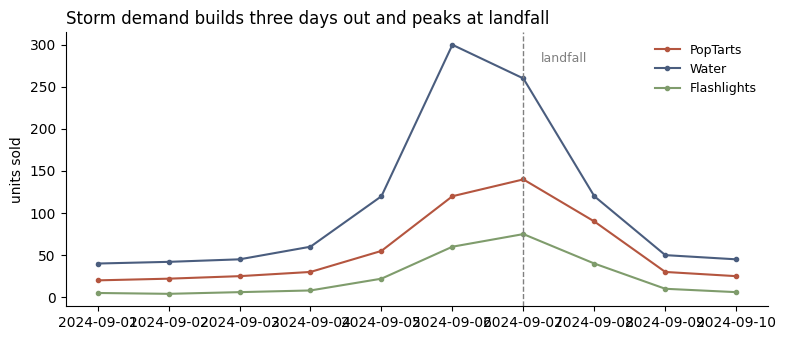

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

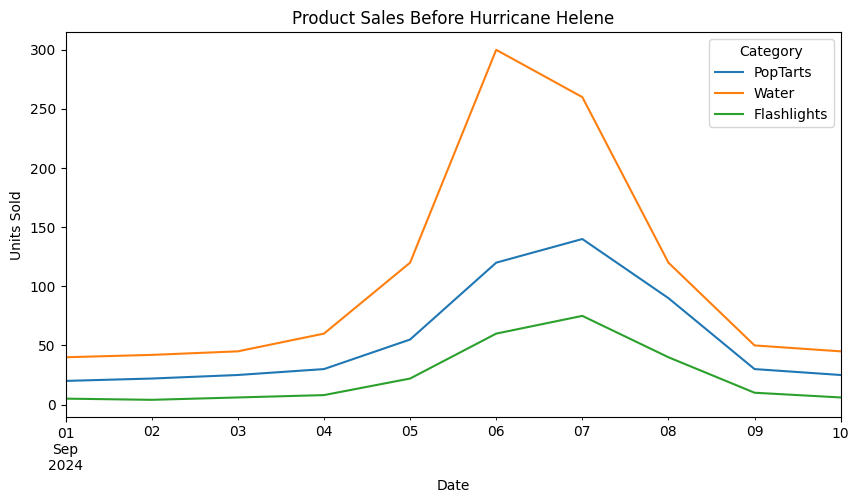

In [3]:
#ToDo
top = daily.loc[PEAK_START:PEAK_END].mean().nlargest(5).index

daily[top].plot(figsize=(10, 5))

plt.axvline(LANDFALL, color='red', linestyle='--')

plt.title('Product Sales Before Hurricane Helene')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend(title='Category')
plt.show()

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

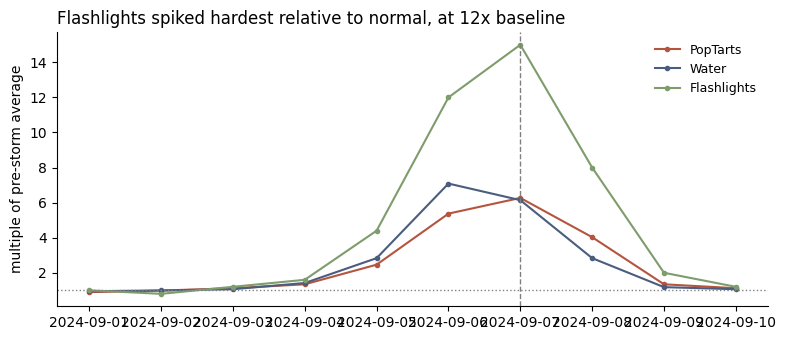

Flashlights    15.0
Water           7.1
PopTarts        6.3
dtype: float64


In [4]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

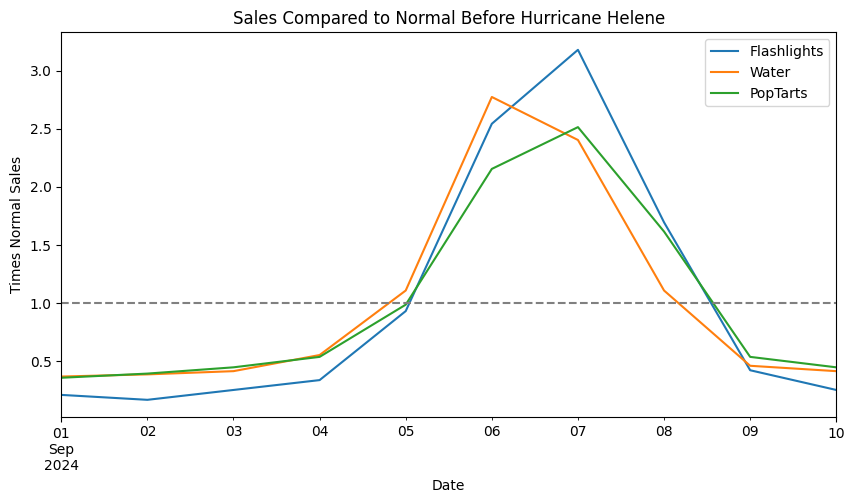

Flashlights    3.177966
Water          2.772643
PopTarts       2.513465
dtype: float64


In [5]:
# TODO
baseline = daily.loc[BASELINE_START:BASELINE_END].mean()

indexed = daily / baseline.replace(0, np.nan)

top = indexed.max().nlargest(5).index

indexed[top].plot(figsize=(10, 5))

plt.axhline(1, color='gray', linestyle='--')
plt.axvline(LANDFALL, color='red', linestyle='--')

plt.title('Sales Compared to Normal Before Hurricane Helene')
plt.xlabel('Date')
plt.ylabel('Times Normal Sales')
plt.show()

print(indexed.max().sort_values(ascending=False))

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

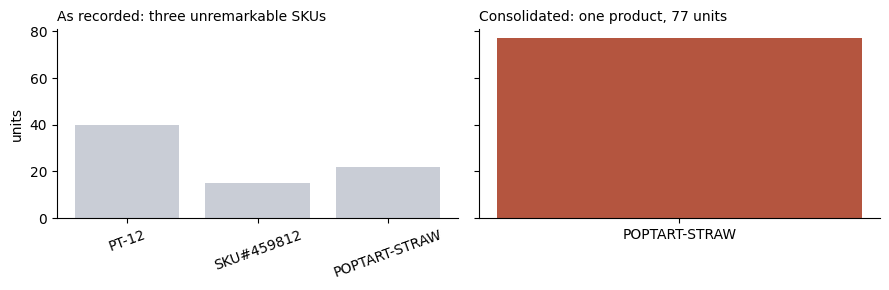

In [6]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

In [7]:
SKU_TO_PRODUCT = {
    'PT-12': 'Pop-Tarts Strawberry',
    'SKU#459812': 'Pop-Tarts Strawberry',
    'POPTART-STRAW': 'Pop-Tarts Strawberry',
    'PT_STRAWBERRY': 'Pop-Tarts Strawberry',
    'WTR-24': 'Bottled Water 24pk',
    'WATER24PK': 'Bottled Water 24pk',
    'WTR_24PK': 'Bottled Water 24pk',
    'BATT-100': 'AA Batteries 4pk',
    'BAT-AA4': 'AA Batteries 4pk',
    'BATT_AA_4PK': 'AA Batteries 4pk',
    'FLASH-01': 'LED Flashlight',
    'LED-FLASH': 'LED Flashlight',
    'BEER-24': 'Light Beer 24pk',
    'LTBEER24': 'Light Beer 24pk',
    'BG-MONO': 'Monopoly',
    'MONOPOLY-01': 'Monopoly',
    'GAME-MONO': 'Monopoly',
    'CARDS-01': 'Playing Cards',
    'PLAYCARD-STD': 'Playing Cards',
    'STREAM-01': 'Streaming Device',
    'ROKU-STD': 'Streaming Device',
    'SOUP-CAN': 'Canned Soup',
    'CNSOUP-01': 'Canned Soup',
    'BREAD-WH': 'White Bread',
    'WHITEBREAD': 'White Bread',
    'PB-16': 'Peanut Butter',
    'PNUTBTR-16': 'Peanut Butter',
    'CNDL-EM': 'Emergency Candles',
    'CANDLE-EMRG': 'Emergency Candles',
    'FAID-01': 'First Aid Kit',
    'FIRSTAID-KIT': 'First Aid Kit',
    'CHRG-PORT': 'Portable Charger',
    'PORTCHARGER': 'Portable Charger',
    'CHIPS-VP': 'Chips Variety Pack',
    'CHIPVARIETY': 'Chips Variety Pack',
    'PTOWEL-6': 'Paper Towels',
    'PAPERTOWEL6': 'Paper Towels',
    'TP-12': 'Toilet Paper',
    'TOILETPAPER12': 'Toilet Paper',
    'DIAP-S3': 'Diapers Size 3',
    'DIAPERS-3': 'Diapers Size 3',
    'BFORM-01': 'Infant Formula',
    'BABYFORMULA': 'Infant Formula',
    'TARP-HD': 'Heavy Duty Tarp',
    'HDTARP-01': 'Heavy Duty Tarp'
}

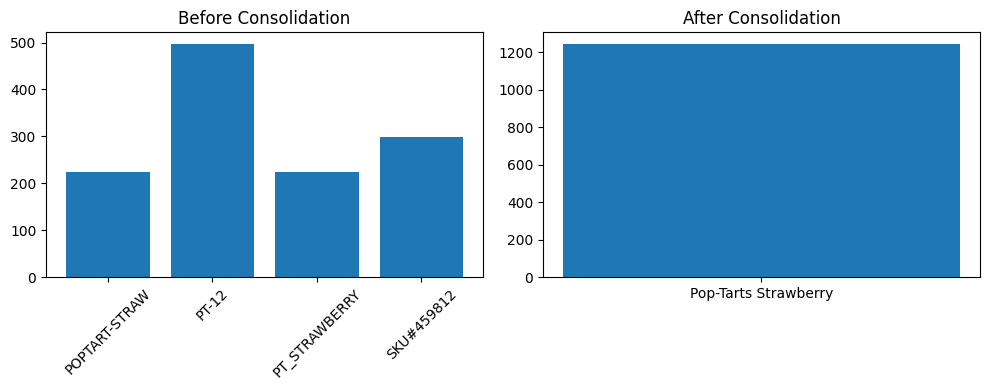

Product: Pop-Tarts Strawberry
Total inventory: 1244
Multiple: 2.5


In [9]:
# TODO
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect('inventory_and_sales.db')

inventory = pd.read_sql('SELECT * FROM inventory_levels', con)
t = inventory.copy()

# Match SKUs to products
t['product'] = t['sku'].map(SKU_TO_PRODUCT)

# Remove unmatched products
t = t.dropna(subset=['product'])

# Use the most recent inventory date
t = t[t['date'] == t['date'].max()]

# Find the product with the most inventory
totals = t.groupby('product')['units_on_hand'].sum()
product = totals.idxmax()

# Compare separate SKUs to combined product
before = t[t['product'] == product].groupby('sku')['units_on_hand'].sum()
after = before.sum()

# Create charts
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(before.index, before.values)
axes[0].set_title('Before Consolidation')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar([product], [after])
axes[1].set_title('After Consolidation')

plt.tight_layout()
plt.show()

# Print results
print('Product:', product)
print('Total inventory:', after)
print('Multiple:', round(after / before.max(), 2))

### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

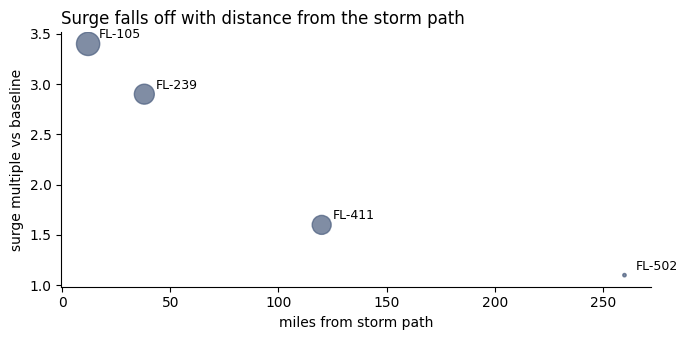

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

In [11]:
# TODO
import pandas as pd

stores = pd.read_csv('store_locations.csv')

print(stores.columns)
print(stores.head())

Index(['store_id', 'store_name', 'city', 'state', 'zip_code', 'latitude',
       'longitude', 'region'],
      dtype='object')
  store_id                             store_name          city    state  \
0   FL-239            Walmart Supercenter Orlando       Orlando       FL   
1   FL-105              Walmart Supercenter Tampa         Tampa       FL   
2   FL-330              Walmart Supercenter Miami         Miami       FL   
3   FL-412       Walmart Supercenter Jacksonville  Jacksonville       FL   
4   FL-287  Walmart Neighborhood Market Kissimmee     Kissimmee  Florida   

   zip_code  latitude  longitude   region  
0     32801   28.5383   -81.3792  Central  
1     33602   27.9506   -82.4572     West  
2     33101   25.7617   -80.1918    South  
3     32099   30.3322   -81.6557    North  
4     34741   28.2920   -81.4076  Central  


### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [13]:
daily = d.groupby(['date', 'category'])['total_units'].sum().unstack()

baseline = daily.loc['2024-09-01':'2024-09-15'].mean()
indexed = daily / baseline.replace(0, np.nan)

top_product = indexed.max().idxmax()
surge_multiple = round(indexed.max().max(), 2)
baseline_window = 'September 1–15, 2024'
charts_ready = 2

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)

top product: Breakfast
surge multiple: 5.66
baseline window: September 1–15, 2024
charts ready: 2


In [14]:
# Checkpoint
top_product = 'Breakfast'         # TODO: your biggest mover
surge_multiple = 5.66        # TODO: how many times baseline
baseline_window = 'September 1–15, 2024'     # TODO: e.g. '14 days before Sept 4'
charts_ready = 2          # TODO: how many presentation-ready charts you have

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)

top product: Breakfast
surge multiple: 5.66
baseline window: September 1–15, 2024
charts ready: 2
